In [15]:
import sys
import numpy as np
import pandas as pd 
import matplotlib.pyplot as plt 
from matplotlib.colors import ListedColormap 
import sklearn 
from sklearn.tree import (DecisionTreeClassifier, DecisionTreeRegressor, plot_tree, export_text ) 
from sklearn.model_selection import (train_test_split, StratifiedKFold, GridSearchCV,    cross_validate ) 
from sklearn.metrics import (accuracy_score, ConfusionMatrixDisplay,    classification_report, mean_absolute_error,    mean_squared_error, r2_score ) 
plt.rcParams.update({'figure.dpi': 110, 'font.size': 11}) 
print('Python:', sys.version.split()[0]) 
print('scikit-learn:', sklearn.__version__)

Python: 3.12.13
scikit-learn: 1.7.2


 hours  practice  passed
     1         0       0
     2         1       0
     3         0       0
     4         2       0
     5         1       1
     6         3       0
     7         1       1
     8         4       0
     9         2       1
    10         5       1
    11         3       1
    12         6       1


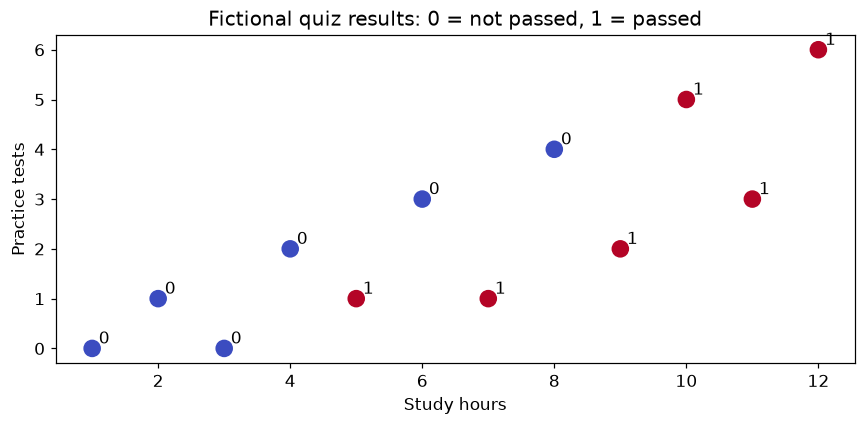

In [16]:
exam = pd.DataFrame({
    'hours': np.arange(1, 13),
    'practice': [0, 1, 0, 2, 1, 3, 1, 4, 2, 5, 3, 6],
    'passed': [0, 0, 0, 0, 1, 0, 1, 0, 1, 1, 1, 1]
})

Xe = exam[['hours', 'practice']]
ye = exam['passed']

print(exam.to_string(index=False))

plt.figure(figsize=(8, 4))

plt.scatter(
    Xe.hours,
    Xe.practice,
    c=ye,
    cmap='coolwarm',
    s=110
)

for i in range(len(exam)):
    plt.annotate(
        str(int(ye.iloc[i])),
        (Xe.hours.iloc[i] + 0.1, Xe.practice.iloc[i] + 0.1)
    )

plt.xlabel('Study hours')
plt.ylabel('Practice tests')
plt.title('Fictional quiz results: 0 = not passed, 1 = passed')

plt.tight_layout()
plt.show()

In [17]:
exam['passed'].value_counts()

passed
0    6
1    6
Name: count, dtype: int64

In [18]:
def entropy(prob):
    sur_1 = -prob*(np.log2(prob))
    sur_2 = -(1-prob)*(np.log2(1-prob))
    return sur_1 + sur_2

In [19]:
entropy(0.5)

np.float64(1.0)

In [21]:
entropy(0.9)

np.float64(0.4689955935892811)

C:\Users\AIML\AppData\Local\Temp\ipykernel_52732\1799763350.py:2: RuntimeWarning: divide by zero encountered in log2
  sur_1 = -prob*(np.log2(prob))
C:\Users\AIML\AppData\Local\Temp\ipykernel_52732\1799763350.py:2: RuntimeWarning: invalid value encountered in multiply
  sur_1 = -prob*(np.log2(prob))


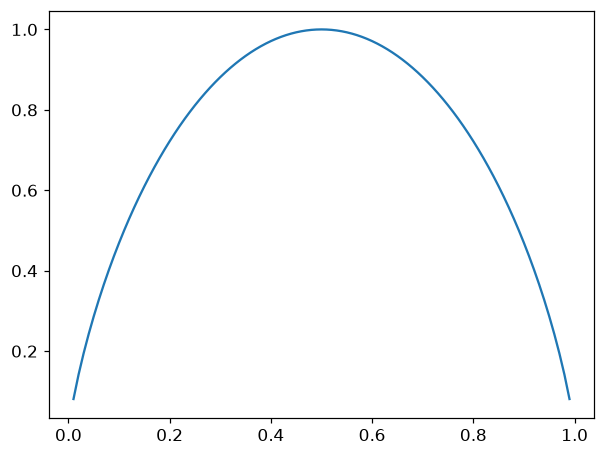

In [22]:
prob_line = np.linspace(0,1,100, endpoint=False)

ent_values = entropy(prob_line)

plt.plot(prob_line, ent_values)

In [24]:
def gini(p):
    return 1 - ((p**2) + ((1-p)**2))


gini(1)

0

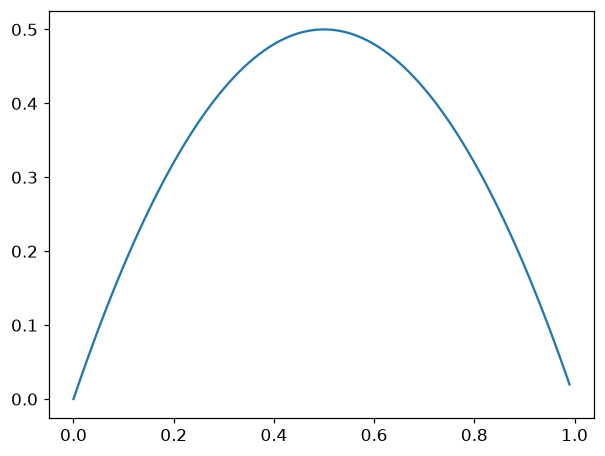

In [25]:
gini_value = gini(prob_line)

plt.plot(prob_line, gini_value)

In [31]:
exam[exam['hours'] <4]['passed'].value_counts()

passed
0    3
Name: count, dtype: int64

In [32]:
gini(1)

0

In [33]:
entropy(0.5)

np.float64(1.0)

In [36]:
entropy(0)

C:\Users\AIML\AppData\Local\Temp\ipykernel_52732\1799763350.py:2: RuntimeWarning: divide by zero encountered in log2
  sur_1 = -prob*(np.log2(prob))
C:\Users\AIML\AppData\Local\Temp\ipykernel_52732\1799763350.py:2: RuntimeWarning: invalid value encountered in scalar multiply
  sur_1 = -prob*(np.log2(prob))


np.float64(nan)

In [37]:
gini(0.6)

0.48

In [38]:
gini(0.4)

0.48

In [39]:
gini(0.8)

0.31999999999999984

In [50]:
entropy(0)

C:\Users\AIML\AppData\Local\Temp\ipykernel_52732\1799763350.py:2: RuntimeWarning: divide by zero encountered in log2
  sur_1 = -prob*(np.log2(prob))
C:\Users\AIML\AppData\Local\Temp\ipykernel_52732\1799763350.py:2: RuntimeWarning: invalid value encountered in scalar multiply
  sur_1 = -prob*(np.log2(prob))


np.float64(nan)

In [41]:
entropy(0.8)

np.float64(0.7219280948873623)

In [42]:
entropy(0.4)

np.float64(0.9709505944546686)

In [43]:
values = np.sort(Xe.hours.unique())
print(values)

[ 1  2  3  4  5  6  7  8  9 10 11 12]


In [44]:
thresholds = (values[:-1] + values[1:]) / 2
print("candidates: ", thresholds)

candidates:  [ 1.5  2.5  3.5  4.5  5.5  6.5  7.5  8.5  9.5 10.5 11.5]


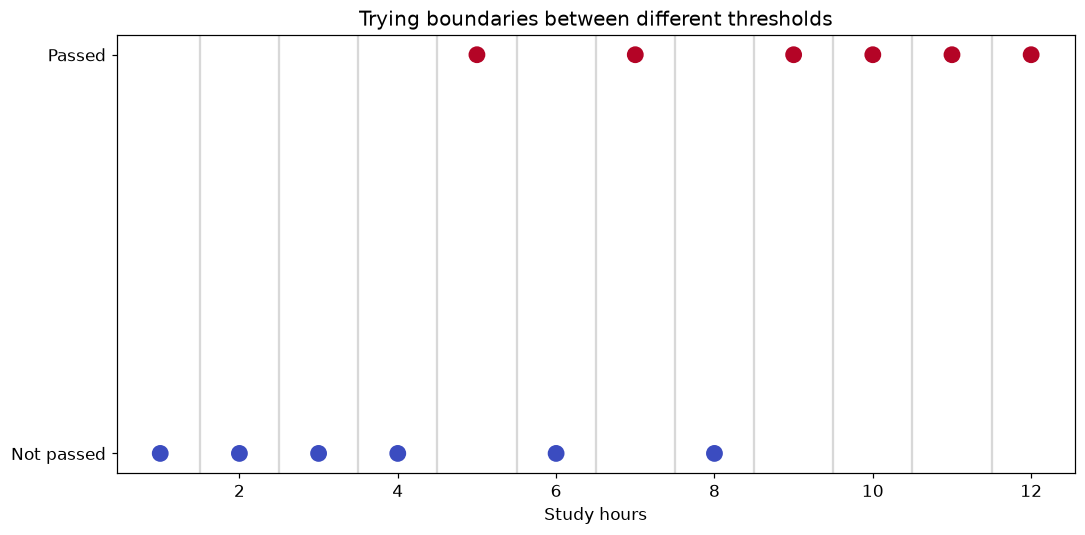

In [45]:
plt.figure(figsize = (10,5))
plt.scatter(Xe.hours, ye, c = ye, cmap = 'coolwarm', s=100)
for t in thresholds:
    plt.axvline(t, color = 'grey', alpha = 0.3)

plt.yticks([0,1], ['Not passed', 'Passed'])
plt.xlabel("Study hours")
plt.title("Trying boundaries between different thresholds")
plt.tight_layout()
plt.show()

In [46]:
gini(0.75)

0.375

In [47]:
gini(1)

0

In [48]:
entropy(0.5)

np.float64(1.0)

## Calculate gini reduction for each threshold

In [51]:
def gini(labels):
    _, counts = np.unique(labels, return_counts=True)
    p = counts / counts.sum()
    return 1 - np.sum(p**2)

rows = []
for t in thresholds:
    left = ye[Xe.hours <= t]
    right = ye[Xe.hours > t]
    child = (len(left)*gini(left) + len(right)*gini(right)) / len(ye)
    rows.append([t, len(left), len(right), child, gini(ye)-child])

split_table = pd.DataFrame(rows, columns = [
    'threshold', 'n_left', 'n_right', 'child_gini', 'gini_decrease'
])

print(split_table.round(4).to_string(index = False))






 threshold  n_left  n_right  child_gini  gini_decrease
       1.5       1       11      0.4545         0.0455
       2.5       2       10      0.4000         0.1000
       3.5       3        9      0.3333         0.1667
       4.5       4        8      0.2500         0.2500
       5.5       5        7      0.3714         0.1286
       6.5       6        6      0.2778         0.2222
       7.5       7        5      0.3714         0.1286
       8.5       8        4      0.2500         0.2500
       9.5       9        3      0.3333         0.1667
      10.5      10        2      0.4000         0.1000
      11.5      11        1      0.4545         0.0455


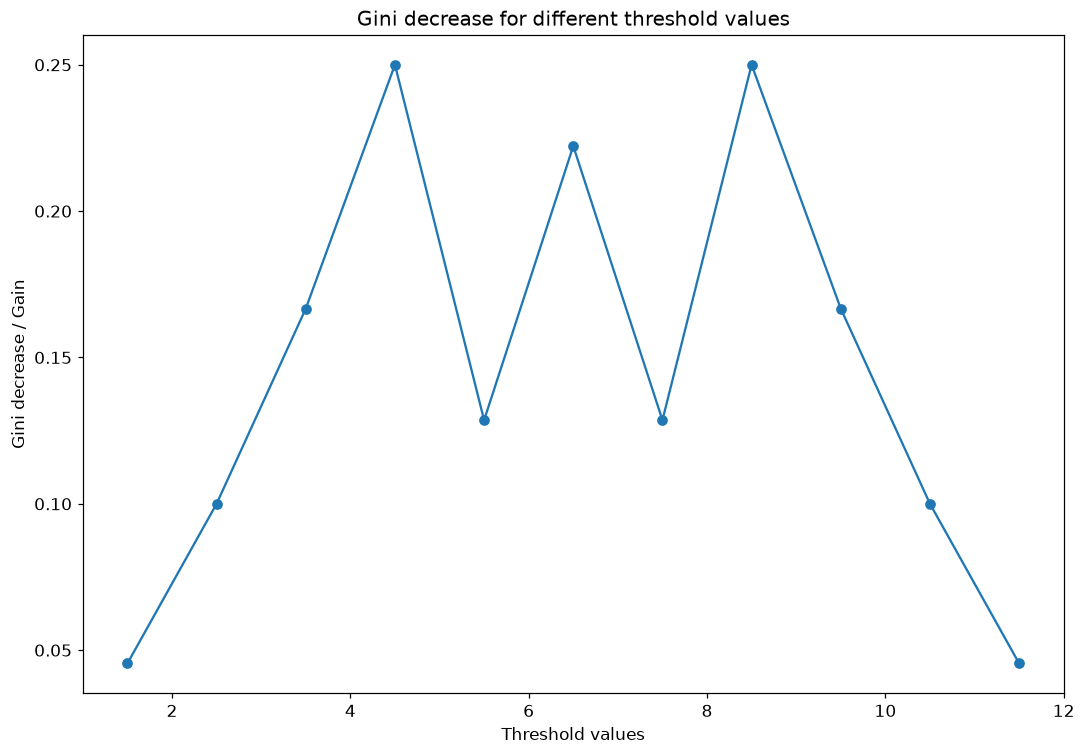

In [52]:
plt.figure(figsize = (10,7))
plt.plot(split_table.threshold, split_table.gini_decrease, 'o-')
plt.xlabel('Threshold values')
plt.ylabel('Gini decrease / Gain')
plt.title("Gini decrease for different threshold values")
plt.tight_layout()
plt.show()


In [ ]:
tree = DecisionTreeClassifier(max_depth = 1, random_state=42)
tree.fit(Xe[['hours']], ye)
print('Tree threshold value: ', tree.tree_.threshold[0])


Tree threshold value:  4.5


In [54]:
print("Tree root gini: ", tree.tree_.impurity[0])

Tree root gini:  0.5


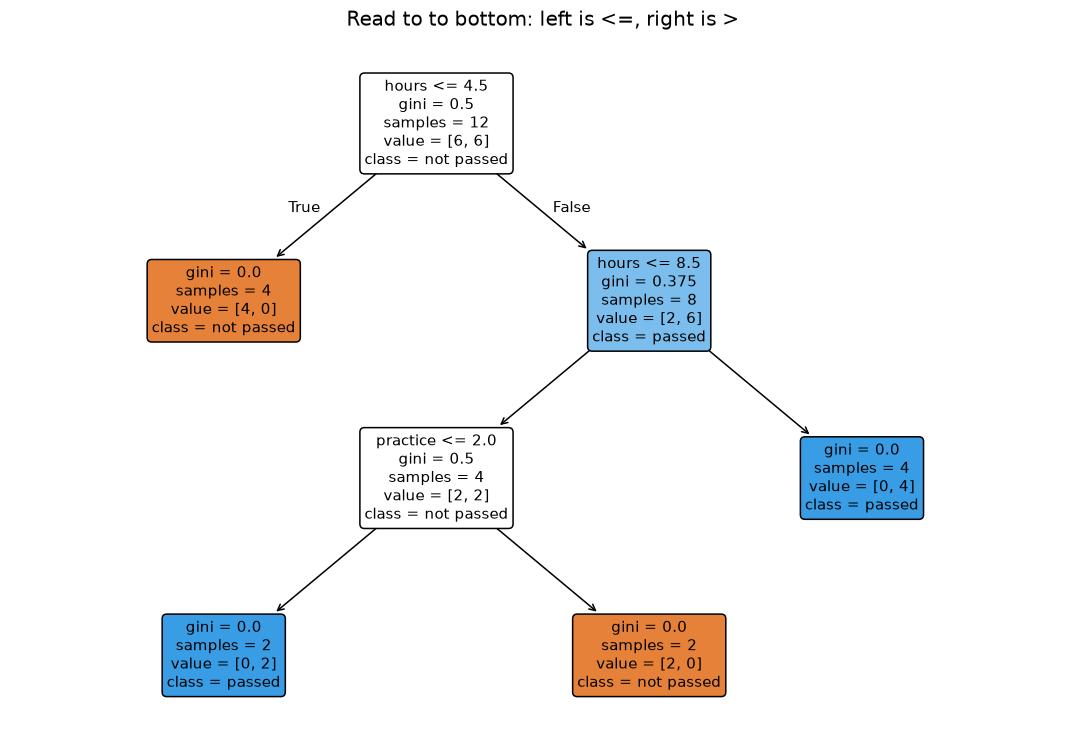

|--- hours <= 4.50
|   |--- class: 0
|--- hours >  4.50
|   |--- hours <= 8.50
|   |   |--- practice <= 2.00
|   |   |   |--- class: 1
|   |   |--- practice >  2.00
|   |   |   |--- class: 0
|   |--- hours >  8.50
|   |   |--- class: 1



In [55]:
exam_tree = DecisionTreeClassifier(max_depth = 3, random_state=42)
exam_tree.fit(Xe, ye)
plt.figure(figsize=(10,7))
plot_tree(exam_tree, feature_names=list(Xe.columns),
          class_names=['not passed', 'passed'],
          filled = True, rounded=True, fontsize=10)
plt.title("Read to to bottom: left is <=, right is >")
plt.tight_layout()
plt.show()
print(export_text(exam_tree, feature_names = list(Xe.columns)))